# Tutorial 3b: Advanced Optimization


Building on [Tutorial 3a](Tutorial_3a_Simple_Optimization.ipynb), this tutorial demonstrates further optimization functionalities including:

- Various operand types (paraxial, real ray-based, aberrations)
- Various variable types (radii, thickness, conic)
- Global optimization (e.g. dual annealing, differential evolution, SHGO, basin-hopping)

In [1]:
import numpy as np

from optiland import analysis, optic, optimization

Let's define a non-optimized doublet, which we will optimize. Our goal in optimization will be to:

- Control distortion via real ray intersection operands
- Minimize spherical aberration
- Minimize the spot size for each field
- Maintain a focal length of 50 mm

In [2]:
lens = optic.Optic()

lens.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
lens.surfaces.add(index=1, radius=50, thickness=5, material="N-BK7")
lens.surfaces.add(index=2, radius=-500, thickness=10)
lens.surfaces.add(index=3, radius=500, thickness=5, material="SK16", is_stop=True)
lens.surfaces.add(index=4, radius=-50, thickness=35)
lens.surfaces.add(index=5)

# add aperture
lens.set_aperture(aperture_type="EPD", value=8)

# add field
lens.fields.set_type(field_type="angle")
lens.fields.add(y=0)
lens.fields.add(y=5.6)
lens.fields.add(y=8)

# add wavelength
lens.wavelengths.add(value=0.4861327)
lens.wavelengths.add(value=0.5875618, is_primary=True)
lens.wavelengths.add(value=0.6562725)

lens.updater.update_paraxial()

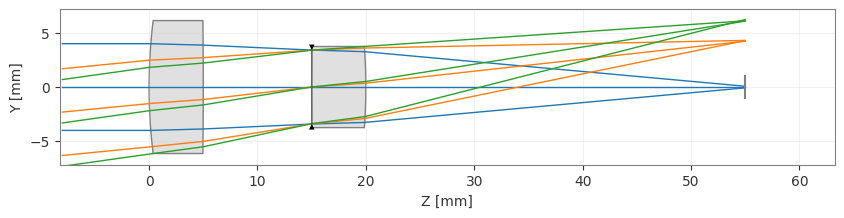

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [3]:
lens.draw()

Let's define the optimization problem. First, let's add the operands:

In [4]:
problem = optimization.OptimizationProblem()

# add real ray operands - the intersection location is f*tan(theta), where f is the
# focal length and theta is the field half angle
input_data = {
    "optic": lens,
    "surface_number": 5,
    "Hx": 0,
    "Hy": 0.7,
    "Px": 0,
    "Py": 0,
    "wavelength": 0.5875618,
}
problem.add_operand(
    operand_type="real_y_intercept",
    target=4.903,
    weight=1,
    input_data=input_data,
)

input_data = {
    "optic": lens,
    "surface_number": 5,
    "Hx": 0,
    "Hy": 1,
    "Px": 0,
    "Py": 0,
    "wavelength": 0.5875618,
}
problem.add_operand(
    operand_type="real_y_intercept",
    target=7.027,
    weight=1,
    input_data=input_data,
)

# add operand to minimize spherical aberration - we will minimize the first
# seidel aberration (i.e. #1)
input_data = {"optic": lens, "seidel_number": 1}
problem.add_operand(operand_type="seidel", target=0, weight=1, input_data=input_data)

# add RMS spot size operand - let's minimize the spot size for each field at the
# primary wavelength we choose a 'uniform' distribution, so the number of rays actually
# means the rays on one axis. So, we actually trace ≈16^2 rays here.
for field in lens.fields.get_field_coords():
    input_data = {
        "optic": lens,
        "surface_number": 5,
        "Hx": field[0],
        "Hy": field[1],
        "num_rays": 16,
        "wavelength": 0.5875618,
        "distribution": "uniform",
    }
    problem.add_operand(
        operand_type="rms_spot_size",
        target=0,
        weight=10,
        input_data=input_data,
    )

# add focal length target
problem.add_operand(operand_type="f2", target=50, weight=1, input_data={"optic": lens})

Now, we can add the variables. Let's let one of the surfaces' conic constant vary. Lastly, we print the optimization problem information overview.

In [5]:
# thickness between the lenses and distance to image plane
problem.add_variable(lens, "thickness", surface_number=2, min_val=3, max_val=30)
problem.add_variable(lens, "thickness", surface_number=4, min_val=0, max_val=100)

# radii of all lenses
problem.add_variable(lens, "radius", surface_number=1, min_val=-1000, max_val=1000)
problem.add_variable(lens, "radius", surface_number=2, min_val=-1000, max_val=1000)
problem.add_variable(lens, "radius", surface_number=3, min_val=-1000, max_val=1000)
problem.add_variable(lens, "radius", surface_number=4, min_val=-1000, max_val=1000)

# conic constant of first lens surface
problem.add_variable(lens, "conic", surface_number=1, min_val=-10, max_val=10)

# print optimization problem info
problem.info()

╒════╤════════════════════════╤═══════════════════╕
│    │   Merit Function Value │   Improvement (%) │
╞════╪════════════════════════╪═══════════════════╡
│  0 │                32.7385 │                 0 │
╘════╧════════════════════════╧═══════════════════╛
╒════╤══════════════════╤══════════╤══════════════╤══════════════╤══════════╤═══════════════╤═════════╤═════════╤════════════════╕
│    │ Operand Type     │   Target │ Min. Bound   │ Max. Bound   │   Weight │   Eff. Weight │   Value │   Delta │   Contrib. [%] │
╞════╪══════════════════╪══════════╪══════════════╪══════════════╪══════════╪═══════════════╪═════════╪═════════╪════════════════╡
│  0 │ real y intercept │    4.903 │              │              │        1 │             1 │   4.234 │  -0.669 │           1.37 │
│  1 │ real y intercept │    7.027 │              │              │        1 │             1 │   6.081 │  -0.946 │           2.73 │
│  2 │ seidel           │    0     │              │              │        1 │        

Let's optimize our system. There are many optimizers available, but we want to demonstrate a global optimization method: Differential Evolution. Optiland utilizes the scipy implementation of this optimization method.

This method can take some time, so we spread the work over several CPU cores with the `workers` argument. Here we use 4 workers. `workers=-1` uses every core, but each worker process holds its own copy of the system, so on a machine with many cores and limited RAM it can use a lot of memory. Start small and increase it if you have memory to spare.

In [6]:
optimizer = optimization.DifferentialEvolution(problem)
# optimizer = optimization.SHGO(problem)  # note SHGO requires bounds
# optimizer = optimization.BasinHopping(problem)  # note BasinHopping requires no bounds

res = optimizer.optimize(maxiter=256, disp=False, workers=4)

C:\Users\kdani\Documents\Python_Scripts\optiland\.venv\Lib\site-packages\scipy\optimize\_differentialevolution.py:487: UserWarning: differential_evolution: the 'workers' keyword has overridden updating='immediate' to updating='deferred'
  with DifferentialEvolutionSolver(func, bounds, args=args,


Let's see how the lens has changed after optimization:

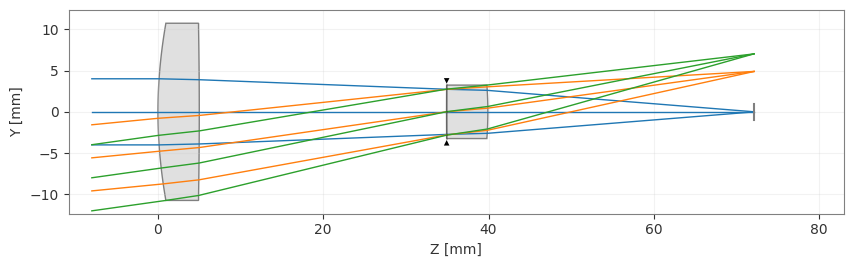

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [7]:
lens.draw()

By viewing the problem info, we can see that there was a greater than 99% improvement in performance, based on the defined operands.

In [8]:
problem.info()

╒════╤════════════════════════╤═══════════════════╕
│    │   Merit Function Value │   Improvement (%) │
╞════╪════════════════════════╪═══════════════════╡
│  0 │             0.00981453 │             99.97 │
╘════╧════════════════════════╧═══════════════════╛
╒════╤══════════════════╤══════════╤══════════════╤══════════════╤══════════╤═══════════════╤═════════╤═════════╤════════════════╕
│    │ Operand Type     │   Target │ Min. Bound   │ Max. Bound   │   Weight │   Eff. Weight │   Value │   Delta │   Contrib. [%] │
╞════╪══════════════════╪══════════╪══════════════╪══════════════╪══════════╪═══════════════╪═════════╪═════════╪════════════════╡
│  0 │ real y intercept │    4.903 │              │              │        1 │             1 │   4.893 │  -0.01  │           1.1  │
│  1 │ real y intercept │    7.027 │              │              │        1 │             1 │   7.015 │  -0.012 │           1.42 │
│  2 │ seidel           │    0     │              │              │        1 │        

Let's perform a few analyses to check the final performance of our lens.

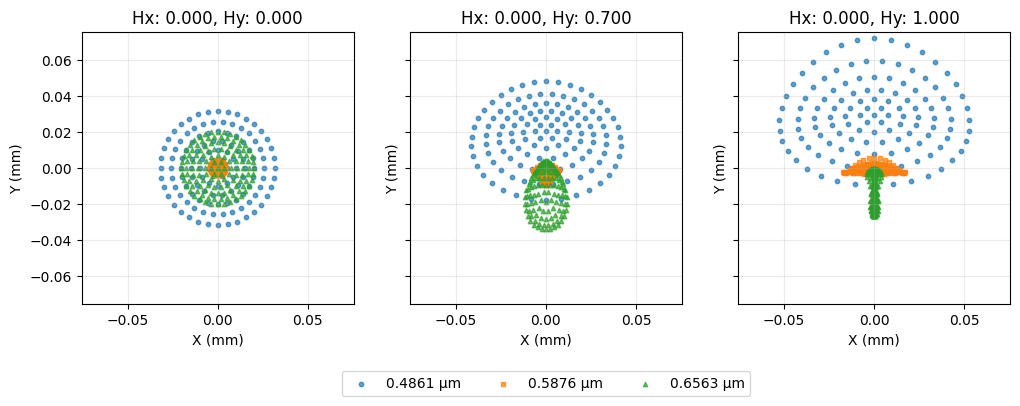

(<Figure size 1200x400 with 3 Axes>,
 [<Axes: title={'center': 'Hx: 0.000, Hy: 0.000'}, xlabel='X (mm)', ylabel='Y (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 0.700'}, xlabel='X (mm)', ylabel='Y (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 1.000'}, xlabel='X (mm)', ylabel='Y (mm)'>])

In [9]:
spot = analysis.SpotDiagram(lens)
spot.view()

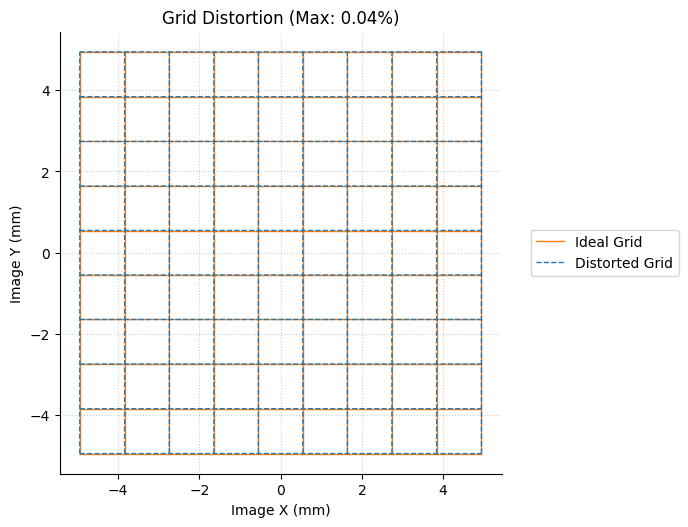

(<Figure size 700x700 with 1 Axes>,
 <Axes: title={'center': 'Grid Distortion (Max: 0.04%)'}, xlabel='Image X (mm)', ylabel='Image Y (mm)'>)

In [10]:
grid = analysis.GridDistortion(lens)
grid.view()

In [11]:
print("Seidel Aberrations:")
for k, seidel in enumerate(lens.aberrations.seidels()):
    print(f"\tS{k + 1}: {seidel:.3e}")

Seidel Aberrations:
	S1: -2.088e-04
	S2: -1.219e-03
	S3: 2.711e-03
	S4: -5.116e-03
	S5: -2.131e-04


Conclusions:

- We showed several different operands and variables that can be used in optimization.
- We demonstrated the use of differential evolution for optimization
- While the lens itself improved in performance, there is still room for improvement. Different operands, variables, or sequences of optimization steps would result in different, and possibly better, results.